In [1]:
%reload_ext autoreload
%autoreload 2

In [2]:
%load_ext line_profiler

In [3]:
import json
import os
import sys
sys.path.insert(0, os.path.abspath('../src/'))

import matplotlib.pyplot as plt
%matplotlib inline

import torch

In [4]:
from predict import Model
from predict import load_data
from utils import imsetshow

## 1.0 Configuration

In [33]:
config_file_path = "config/config.json"
# with open(config_file_path, "r") as read_file:
#     config = json.load(read_file)
    
# checkpoint_dir = config["paths"]["checkpoint_dir"]
# run_subfolder = 'batch_32_views_32_min_32_beta_50.0_time_2026-11-05-20-54-05-929765'
# checkpoint_filename = 'HRNet.pth'
# checkpoint_file = os.path.join(checkpoint_dir, run_subfolder, checkpoint_filename)
# # print(checkpoint_file)
# assert os.path.isfile(checkpoint_file)

In [15]:
import os

project_root = "/home/iit/Desktop/Aviral_MS/HighRes-net"
os.chdir(project_root)

checkpoint_file = os.path.join(
    "models",
    "weights",
    run_subfolder,
    "HRNet.pth"
)

print("Current directory:", os.getcwd())
print("Checkpoint exists:", os.path.isfile(checkpoint_file))

Current directory: /home/iit/Desktop/Aviral_MS/HighRes-net
Checkpoint exists: True


## 1.1 Load model

In [16]:
import os

print("Current directory:", os.getcwd())
print("Checkpoint path:", os.path.abspath(checkpoint_file))
print("Exists:", os.path.isfile(checkpoint_file))

Current directory: /home/iit/Desktop/Aviral_MS/HighRes-net
Checkpoint path: /home/iit/Desktop/Aviral_MS/HighRes-net/models/weights/batch_32_views_32_min_32_beta_50.0_time_2026-11-05-20-54-05-929765/HRNet.pth
Exists: True


In [17]:
model = Model(config)
model.load_checkpoint(checkpoint_file=checkpoint_file)

## 1.2 Load data

In [18]:
train_dataset, val_dataset, test_dataset, baseline_cpsnrs = load_data(config_file_path, val_proportion=0.10, top_k=-1)

## 1.3 Run evaluation

In [19]:
results = model.evaluate(train_dataset, val_dataset, test_dataset, baseline_cpsnrs)

  0%|          | 0/729 [00:00<?, ?it/s]

  0%|          | 0/82 [00:00<?, ?it/s]

  0%|          | 0/290 [00:00<?, ?it/s]

## 1.4 Benchmark % ESA Baseline

In [20]:
results.describe().T

,count,mean,std,min,25%,50%,75%,max
ESA,1450.0,46.378919,3.779463,31.449051,43.939710,46.308704,48.645906,59.720023
model,811.0,48.593918,3.453378,39.006279,46.175051,48.560978,50.627674,59.816479
score,811.0,0.955443,0.029303,0.811123,0.943258,0.958957,0.973535,1.040878
mean_clr,1101.0,15212.525337,764.974870,9179.000000,14930.176471,15362.000000,15720.096774,16305.888889
std_clr,1101.0,1459.779438,454.747976,172.300476,1188.300687,1495.344583,1778.862007,4105.439616


In [22]:
results.loc[results['part'] == 'train'].describe().loc['mean']

ESA            46.483263
model          48.633300
score           0.955455
mean_clr    15186.890685
std_clr      1481.189325
Name: mean, dtype: float64

In [23]:
results.loc[results['part'] == 'val'].describe().loc['mean']

ESA            46.099426
model          48.243800
score           0.955341
mean_clr    15067.615376
std_clr      1508.980929
Name: mean, dtype: float64

In [24]:
results.loc[results['part'] == 'test'].describe().loc['mean']

ESA            45.936790
model                NaN
score                NaN
mean_clr    15317.940090
std_clr      1392.047263
Name: mean, dtype: float64

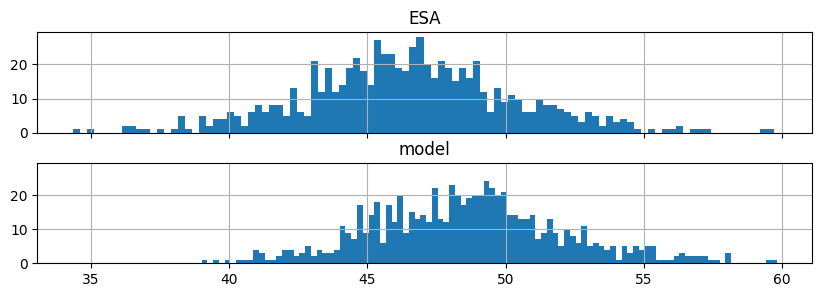

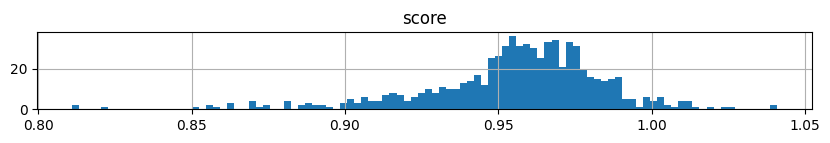

In [25]:
results.loc[results['part']=='train'].hist(column=['ESA', 'model'],
                                           sharex=True, sharey=True, bins=100, layout=(2,1), figsize=(10, 3));
results.loc[results['part']=='train'].hist(column=['score'],
                                           bins=100, figsize=(10, 1));

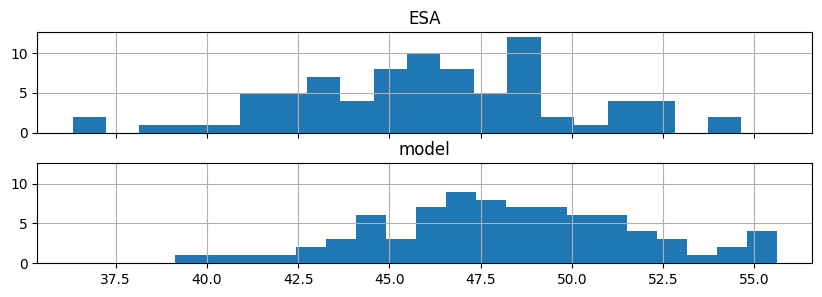

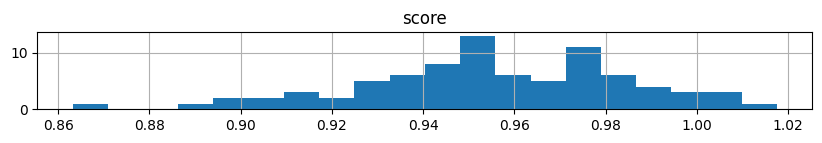

In [26]:
results.loc[results['part']=='val'].hist(column=['ESA', 'model'],
                                           sharex=True, sharey=True, bins=20, layout=(2,1), figsize=(10, 3));
results.loc[results['part']=='val'].hist(column=['score'],
                                           bins=20, figsize=(10, 1));

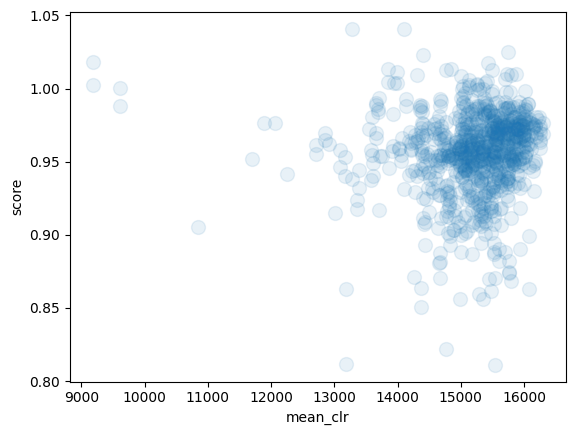

In [27]:
results.plot.scatter('mean_clr', 'score', s=100, alpha=.1);

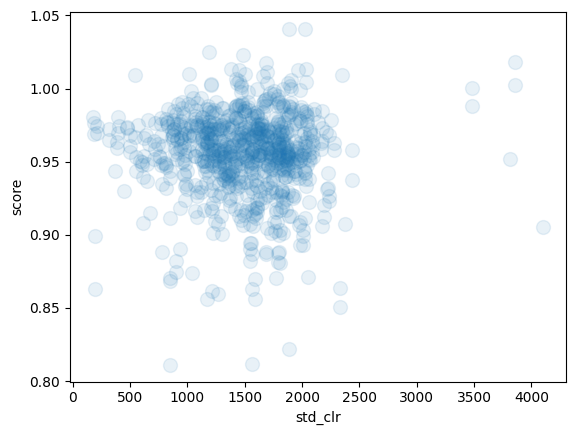

In [28]:
results.plot.scatter('std_clr', 'score', s=100, alpha=.1);

## 1.5 Pretty pics

In [29]:
results[results['part'] == 'val'].sort_values('score')

,ESA,model,clr,part,score,mean_clr,std_clr
imgset0894,36.317932,42.076565,"[15192, 14839, 14821, 14753, 14534, 14522, 144...",val,0.863139,13177.115385,1561.975458
imgset0372,42.605861,47.960686,"[16384, 16384, 16384, 16376, 16372, 16345, 163...",val,0.888350,15522.750000,1681.283668
imgset0831,41.265511,46.147865,"[16384, 16384, 16383, 16371, 16371, 16371, 163...",val,0.894202,15522.750000,1547.630373
imgset0773,42.867669,47.666672,"[16384, 16384, 16384, 16372, 16367, 16358, 163...",val,0.899322,14835.958333,2007.443824
imgset1119,44.644945,49.197876,"[16226, 16196, 16189, 16180, 16179, 16162, 161...",val,0.907457,15282.379310,1265.347585
...,...,...,...,...,...,...,...
imgset0717,52.252475,52.372623,"[16384, 16384, 16384, 16384, 16384, 16384, 163...",val,0.997706,15720.096774,1523.988472
imgset0905,45.883833,45.708069,"[16282, 16123, 16059, 16056, 15999, 15579, 154...",val,1.003845,13996.750000,1697.163866
imgset1082,48.338322,48.051968,"[16384, 16384, 16384, 16384, 16384, 16372, 163...",val,1.005959,15132.142857,1903.564245
imgset0123,50.980298,50.517353,"[16384, 16384, 16384, 16374, 16300, 16002, 156...",val,1.009164,15800.307692,539.493692


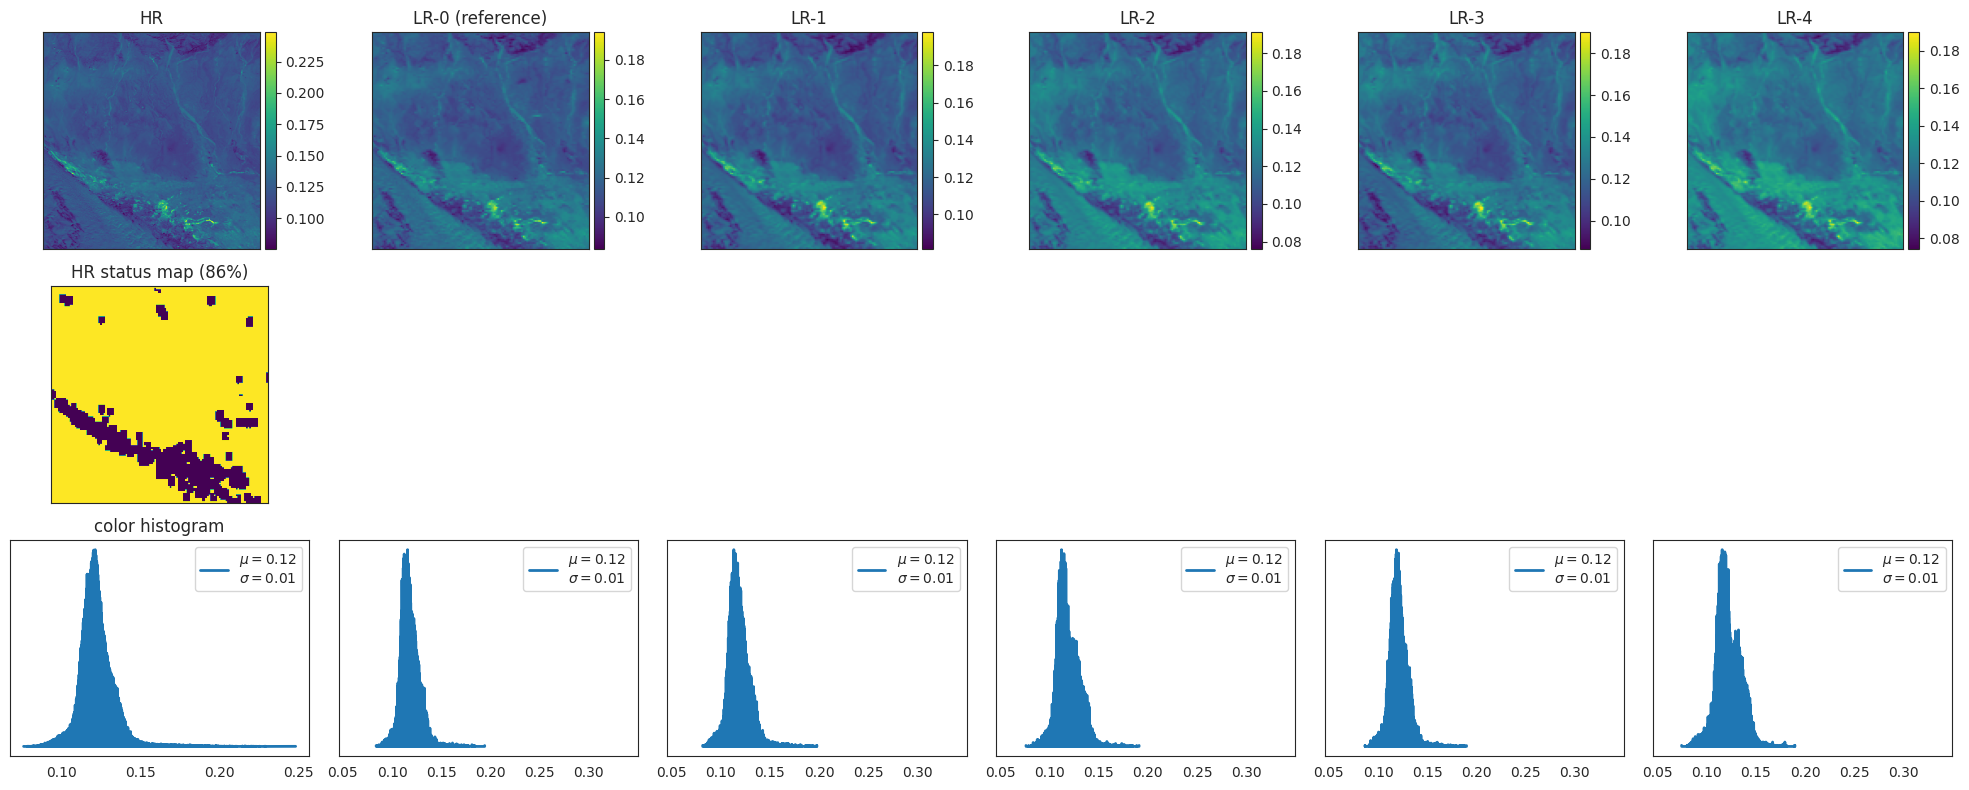

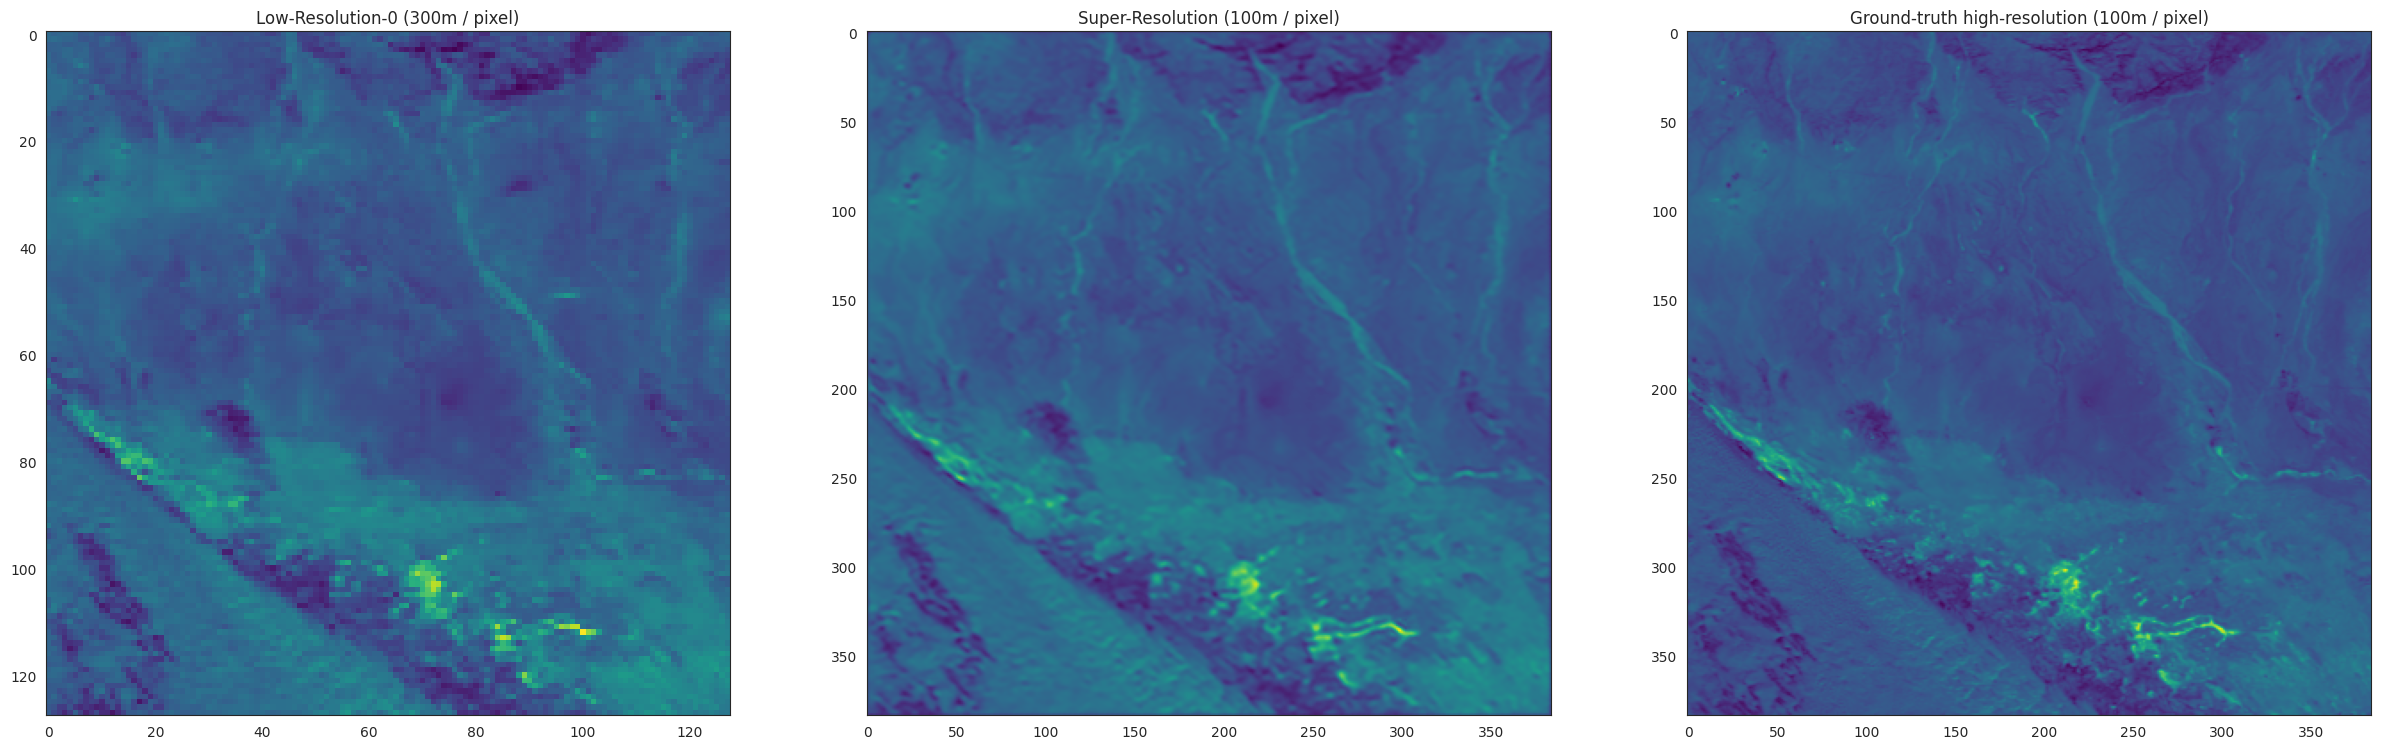

In [37]:
imset = val_dataset['imgset0532']
sr, scPSNR = model(imset)

imsetshow(imset, k=5, figsize=(20,8), resample=False, show_histogram=True, show_map=True)

plt.figure(figsize=(30, 10))
plt.subplot(131);  plt.imshow(imset['lr'][0]);  plt.title('Low-Resolution-0 (300m / pixel)');
plt.subplot(132);  plt.imshow(sr);  plt.title('Super-Resolution (100m / pixel)');
plt.subplot(133);  plt.imshow(imset['hr']);  plt.title('Ground-truth high-resolution (100m / pixel)');

In [36]:
# print("Number of validation image sets:", len(val_dataset))
# print("Available image sets:")
# print(list(val_dataset.name_to_dir.keys())[:30])

Number of validation image sets: 82
Available image sets:
['imgset0290', 'imgset0079', 'imgset0162', 'imgset1087', 'imgset0585', 'imgset0878', 'imgset0028', 'imgset0986', 'imgset0817', 'imgset0902', 'imgset1044', 'imgset0372', 'imgset0532', 'imgset0433', 'imgset0168', 'imgset1019', 'imgset0918', 'imgset1052', 'imgset1017', 'imgset0123', 'imgset0664', 'imgset1009', 'imgset1094', 'imgset1146', 'imgset0463', 'imgset0621', 'imgset1029', 'imgset0308', 'imgset0063', 'imgset1119']


## 1.6 Generate submission file

In [38]:
model.generate_submission_file(imset_dataset=test_dataset, out='../submission')

generating solutions: 

  0%|          | 0/290 [00:00<?, ?it/s]

**************************************************************************************************************************************************************************************************************************************************************************************************
archiving: 
**************************************************************************************************************************************************************************************************************************************************************************************************
done. The submission-file is found at ../submission/submission.zip. Bye!
